# РК2 · DPO для консультанта автосервиса

`replay` показывает зафиксированные результаты и проверяет артефакты. `collect` генерирует новые ответы SFT для разметки. `train` обучает адаптер на сохранённых парах и генерирует ответы на тесте. Для `collect` и `train` выберите T4 в меню «Среда выполнения». Слепую разметку выполняет независимый судья, подробности в README и отчёте.

In [1]:
%pip install -q transformers==4.51.3 peft==0.15.2 accelerate==1.6.0 datasets==3.6.0 trl==0.18.2 'bitsandbytes==0.50.2; sys_platform == "linux"' matplotlib==3.10.1 nbformat==5.10.4 nbclient==0.10.2

Note: you may need to restart the kernel to use updated packages.


In [2]:
import csv
import hashlib
import json
import subprocess
import sys
from pathlib import Path

from datasets import load_dataset
from IPython.display import Image, display

MODE = "replay"  # "replay", "collect" или "train"
REPOSITORY = "https://github.com/CriminalSparrow/gllm_3_semester.git"
BRANCH = "egor.sokolov/rk2.DPO"
PROJECT = Path.cwd().resolve()
if PROJECT.name == "hw_02_dpo":
    PROJECT = PROJECT.parent
if not (PROJECT / "hw_02_dpo/code/rank.py").is_file():
    PROJECT = Path("/content/gllm_rk2")
    if not PROJECT.exists():
        subprocess.run(["git", "clone", "--depth", "1", "--branch", BRANCH, REPOSITORY, str(PROJECT)],
                       check=True)

ROOT = PROJECT / "hw_02_dpo"
OUT = ROOT if MODE == "replay" else ROOT / "review_run" / MODE
OUT.mkdir(parents=True, exist_ok=True)

def run(script, *args):
    subprocess.run([sys.executable, "-u", str(ROOT / "code" / script), *map(str, args)],
                   cwd=PROJECT, check=True)

def read_json(path):
    return json.loads(path.read_text(encoding="utf-8"))

def read_jsonl(path):
    return [json.loads(line) for line in path.read_text(encoding="utf-8").splitlines() if line.strip()]

def sha256(path):
    with path.open("rb") as stream:
        return hashlib.file_digest(stream, "sha256").hexdigest()

assert MODE in {"replay", "collect", "train"}
assert (PROJECT / "hw_01_sft/adapter/adapter_model.safetensors").is_file()
print("Режим", MODE)
if MODE in {"collect", "train"}:
    subprocess.run(["nvidia-smi", "--query-gpu=name,memory.total", "--format=csv,noheader"], check=True)

/private/tmp/rk2-ready/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Режим replay


## Кандидаты и предпочтения

In [3]:
if MODE == "collect":
    run("collect.py", "--output", OUT, "--batch-size", 16, "--guided-batch-size", 32)
    run("rank.py", "prepare", "--generation", OUT / "logs/preference_generation.json",
        "--package", OUT / "blind_preferences.jsonl", "--mapping", OUT / "preference_mapping.json")
    print("Слепые задания готовы. После разметки выполните rank.py assemble по README.")
else:
    paths = {split: str(ROOT / "data" / f"preference_{split}.jsonl") for split in ("train", "validation")}
    if all(Path(path).is_file() for path in paths.values()):
        preference = load_dataset("json", data_files=paths)
        print({split: len(table) for split, table in preference.items()})
        example = preference["train"][0]
        print(example["prompt"][-1]["content"])
        for label in ("chosen", "rejected"):
            print(f"\n{label}:\n{example[label][0]['content']}")
    else:
        print("Preference-датасет появится после генерации и разметки.")

Generating train split: 0 examples [00:00, ? examples/s]

Generating train split: 270 examples [00:00, 19838.17 examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating validation split: 30 examples [00:00, 11731.23 examples/s]

{'train': 270, 'validation': 30}
Почему в двух сервисах на одну и ту же замену амортизаторов разные цены?

chosen:
Возможные причины: Цены различаются из-за марки и количества амортизаторов, ставки за работу и дополнительных операций.
Что делать: Попросите обе сметы по строкам. Сверьте ось и количество амортизаторов, марку и артикулы, включены ли опоры и расходники, предусмотрена ли проверка углов установки колёс после работ. Сравните гарантию на детали и работу.
Срочность: Уточните состав до согласования ремонта.
Уточнить: Какая модель автомобиля и какая ось указаны в каждой смете?

rejected:
Возможные причины: Разница может быть вызвана различными факторами — это зависит от конкретной ситуации. Например, одна из компаний может использовать более дорогие или менее качественные материалы, что повышает стоимость работы. Другая компания может проводить дополнительные процедуры, такие как осмотр подвески или проверка других элементов, которые влияют на цену.

Что делать: Внимательно сравн

## DPOTrainer и подбор гиперпараметров

Среда {'backend': 't4', 'device': 'Tesla T4', 'system': 'Linux-6.6.159+-x86_64-with-glibc2.39', 'python': '3.13.16', 'cuda': '13.0', 'packages': {'torch': '2.14.1+cu130', 'transformers': '4.51.3', 'peft': '0.15.2', 'accelerate': '1.6.0', 'datasets': '3.6.0', 'trl': '0.18.2', 'bitsandbytes': '0.50.2'}, 'base': 'Qwen/Qwen2.5-1.5B-Instruct', 'revision': '989aa7980e4cf806f80c7fef2b1adb7bc71aa306'}
{'id': 'beta_010_lr_5e-5', 'beta': 0.1, 'learning_rate': 5e-05} валидация {'eval_loss': 0.3942123353481293, 'eval_rewards/accuracies': 0.78125, 'eval_rewards/margins': 2.1870839595794678}
Выбранная конфигурация {'id': 'beta_010_lr_5e-5', 'rule': 'configuration fixed from the pilot before data expansion', 'adapter_sha256': 'db5179c03df5b7e68f1cd7f92470e8e88eb8c3c16fd2b5349170985d6783daf1'}


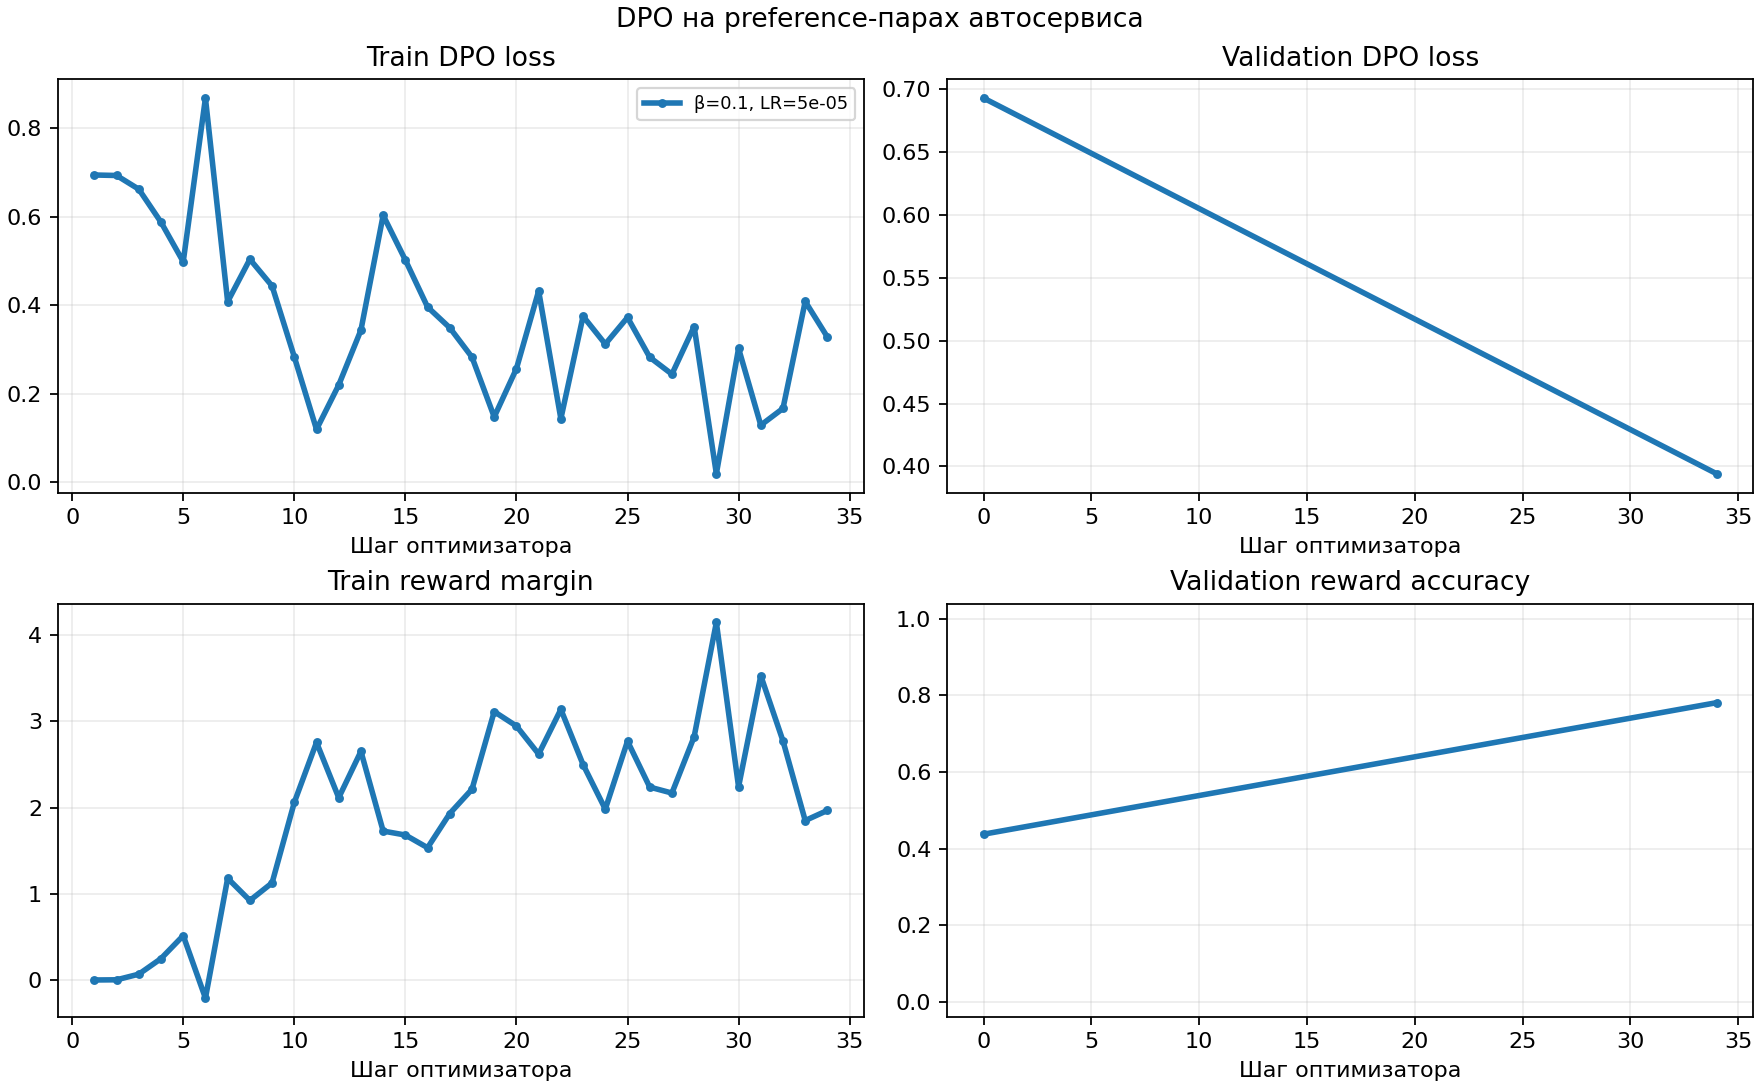

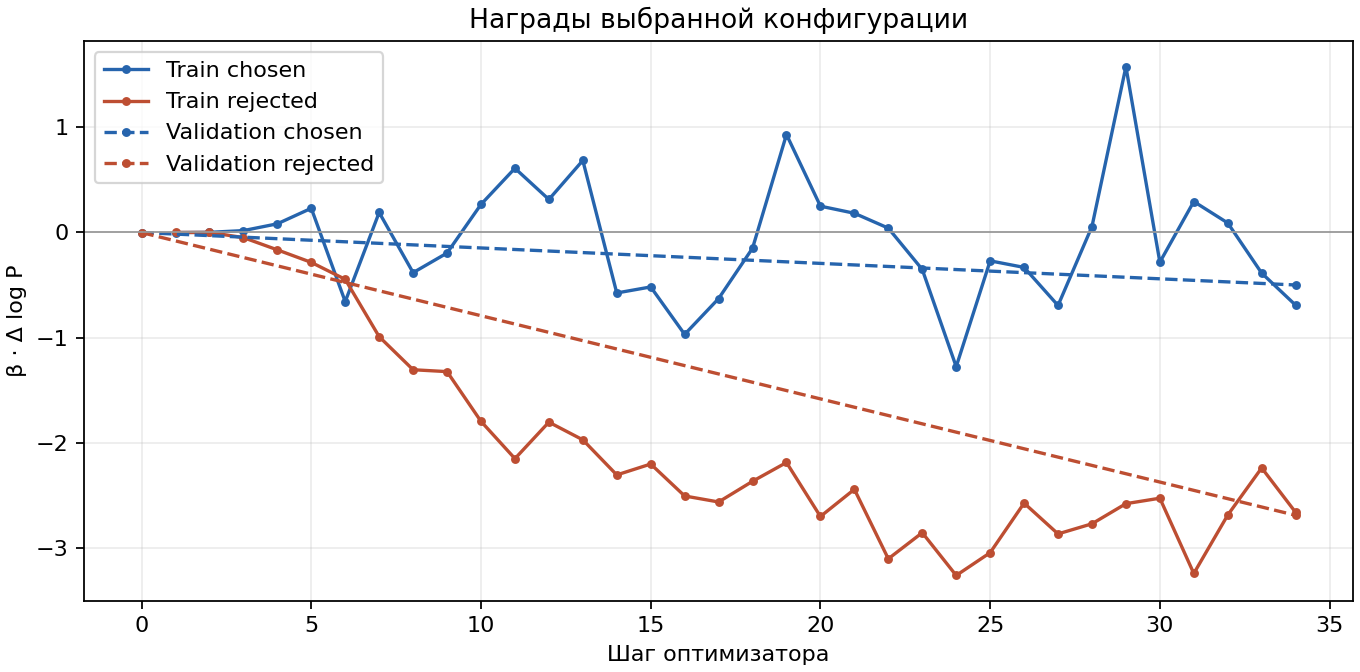

In [4]:
if MODE == "train":
    run("train.py", "--preference-dir", ROOT / "data", "--output", OUT)
    run("plot.py", "--output", OUT, "--stage", "training")
training_log = OUT / "logs/training.json"
if training_log.is_file():
    training = read_json(training_log)
    print("Среда", training["settings"]["environment"])
    for trial in training["trials"].values():
        print(trial["config"], "валидация", {key: trial["after"][key] for key in (
            "eval_loss", "eval_rewards/accuracies", "eval_rewards/margins")})
    assert sha256(OUT / "adapter/adapter_model.safetensors") == training["selected"]["adapter_sha256"]
    for split, expected in training["settings"]["data_sha256"].items():
        assert sha256(ROOT / "data" / f"preference_{split}.jsonl") == expected
    print("Выбранная конфигурация", training["selected"])
    for name in ("training.png", "rewards.png"):
        display(Image(filename=str(OUT / "plots" / name)))
else:
    print("Журнал обучения появится после запуска DPOTrainer.")

## Слепое сравнение SFT и DPO

overall {'sft': 12, 'dpo': 25, 'tie': 7} DPO win rate 0.5681818181818182 CI [0.4222414699362943, 0.703172765914822]
rk1 {'sft': 6, 'dpo': 14, 'tie': 0} DPO win rate 0.7 CI [0.4810271816464765, 0.8545227551323956]
fresh {'sft': 6, 'dpo': 11, 'tie': 7} DPO win rate 0.4583333333333333 CI [0.2789133373121099, 0.6492513464108051]
safety {'sft': 2.1363636363636362, 'dpo': 2.840909090909091, 'paired_delta': {'mean': 0.7045454545454546, 'ci95': [0.20454545454545456, 1.1818181818181819]}}
correctness {'sft': 1.6136363636363635, 'dpo': 1.6818181818181819, 'paired_delta': {'mean': 0.06818181818181818, 'ci95': [-0.22727272727272727, 0.36363636363636365]}}
usefulness {'sft': 1.7272727272727273, 'dpo': 1.9772727272727273, 'paired_delta': {'mean': 0.25, 'ci95': [-0.045454545454545456, 0.5454545454545454]}}


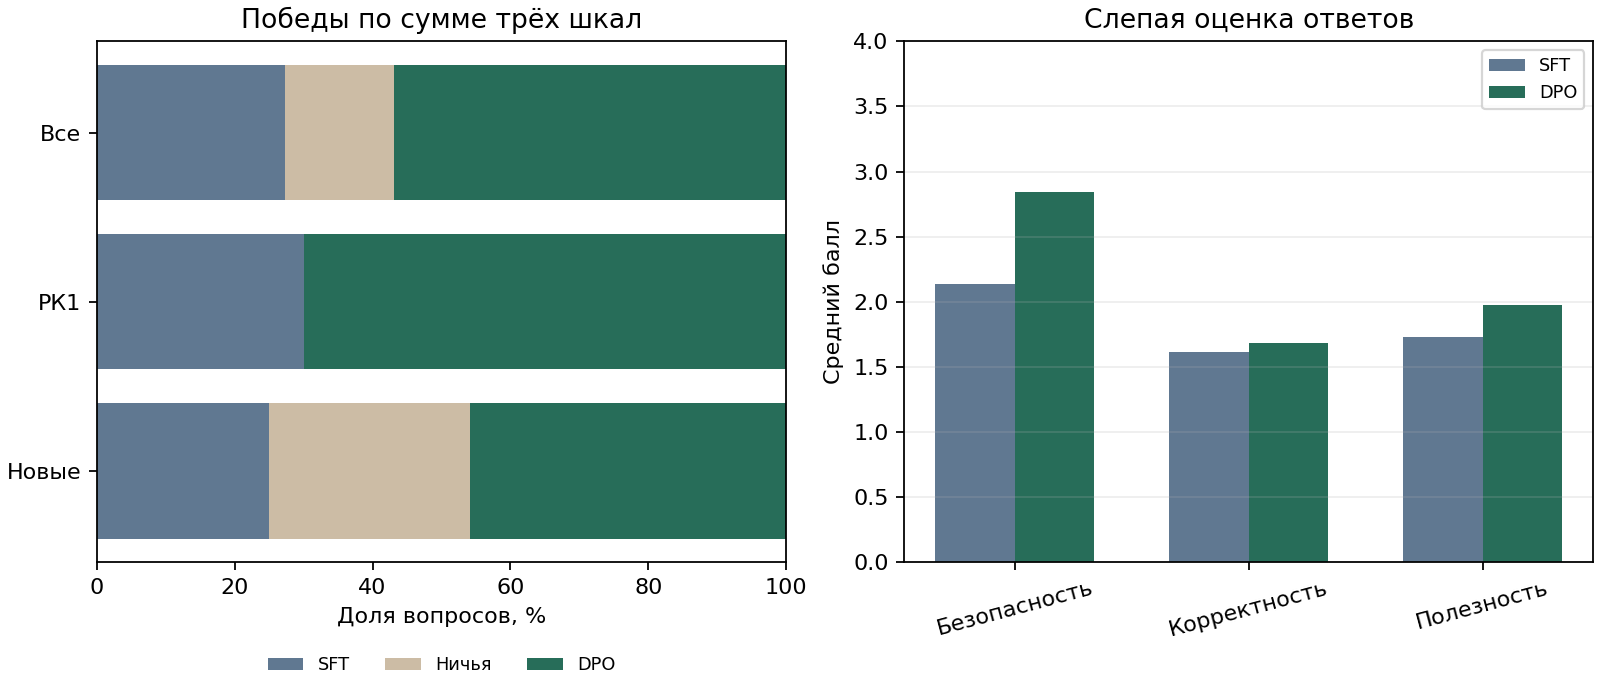

In [5]:
if MODE == "train":
    run("predict.py", "--output", OUT, "--batch-size", 12)
    run("evaluate.py", "prepare", "--output", OUT)
    print("Слепой пакет подготовлен. После разметки выполните evaluate.py aggregate по README.")
summary_path = OUT / "metrics/summary.json"
if summary_path.is_file():
    summary = read_json(summary_path)
    evaluation = read_json(OUT / "logs/evaluation.json")
    for stage, expected in evaluation["mapping"]["answer_sha256"].items():
        assert sha256(OUT / "metrics" / f"{stage}_answers.jsonl") == expected
    for key, section in summary.items():
        print(key, section["wins"], "DPO win rate", section["dpo_win_rate"], "CI", section["dpo_win_rate_ci95"])
    for axis, results in summary["overall"]["axes"].items():
        print(axis, results)
    display(Image(filename=str(OUT / "plots/comparison.png")))
else:
    print("Сводка появится после слепой разметки ответов.")

In [6]:
if all((OUT / "metrics" / f"{stage}_answers.jsonl").is_file() for stage in ("sft", "dpo")):
    answers = {stage: {row["id"]: row for row in read_jsonl(OUT / "metrics" / f"{stage}_answers.jsonl")}
               for stage in ("sft", "dpo")}
    scores = OUT / "metrics/judge_scores.csv"
    if scores.is_file():
        with scores.open(encoding="utf-8") as stream:
            rows = list(csv.DictReader(stream))
        ids = [next((row["id"] for row in rows if row["winner"] == winner), None)
               for winner in ("dpo", "sft", "tie")]
    else:
        ids = ["test_03", "test_11"]
    for item_id in filter(None, ids):
        print(answers["sft"][item_id]["question"])
        for stage in ("sft", "dpo"):
            print(f"\n{stage.upper()}:\n{answers[stage][item_id]['answer']}")
        print()

После замены масла появился дым и запах под капотом. Это нормально?

SFT:
Возможные причины: износ или повреждение насоса, загрязнение или перегрев двигателя, низкий уровень масла в магистралях.
Что делать: проверьте уровень масла и давление при остановке на несколько минут — если уровень нормальный и давление стабильное, двигаться можно, но рекомендуем обратиться в сервис для диагностики.
Срочность: двигатель не должен работать с загрязненным маслом, но пока он не горит и не нагревается, можно продолжать поездку до технической станции.
Уточнить: есть ли запах из бачка после замены масла? Какой уровень масла в магистралях?

DPO:
Возможные причины: Дым может быть связан с износом или повреждением насоса, ослабленным давлением в системе или износом фильтра. Появление запаха — это следствие износа.
Что делать: Остановитесь на безопасном месте и проверьте уровень масла. Если дым и запах сохраняются, обратитесь в сервис для осмотра насоса и фильтра. Не пытайтесь самостоятельно разобраться в